In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('/kaggle/input/datasets/nudratabbas/patient-segmentation-data/patient_segmentation_dataset.csv')

In [3]:
df.head()

,PatientID,Age,Gender,State,City,Height_cm,Weight_kg,BMI,Insurance_Type,Primary_Condition,Num_Chronic_Conditions,Annual_Visits,Avg_Billing_Amount,Last_Visit_Date,Days_Since_Last_Visit,Preventive_Care_Flag
0,P10000,64,Male,GA,Unknown,151,115,50.4,Private,Arthritis,3,7,2995.0,2025-07-18,186,0
1,P10001,59,Male,OH,Unknown,189,68,19.0,Medicare,Depression,1,8,1209.0,2025-12-12,39,0
2,P10002,58,Female,PA,Unknown,156,91,37.4,Private,Asthma,1,4,999.0,2025-09-16,126,0
3,P10003,43,Female,GA,Unknown,152,92,39.8,Medicare,Hypertension,1,6,5638.5,2025-04-09,286,1
4,P10004,53,Female,NC,Unknown,167,51,18.3,Medicaid,Asthma,1,4,5796.0,2025-03-07,319,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   PatientID               2000 non-null   object 
 1   Age                     2000 non-null   int64  
 2   Gender                  2000 non-null   object 
 3   State                   2000 non-null   object 
 4   City                    2000 non-null   object 
 5   Height_cm               2000 non-null   int64  
 6   Weight_kg               2000 non-null   int64  
 7   BMI                     2000 non-null   float64
 8   Insurance_Type          2000 non-null   object 
 9   Primary_Condition       1505 non-null   object 
 10  Num_Chronic_Conditions  2000 non-null   int64  
 11  Annual_Visits           2000 non-null   int64  
 12  Avg_Billing_Amount      2000 non-null   float64
 13  Last_Visit_Date         2000 non-null   object 
 14  Days_Since_Last_Visit   2000 non-null   

In [5]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,50.69550,15.444450,18.0,40.0,51.00,63.250,87.0
Height_cm,2000.0,167.90750,12.684494,145.0,158.0,168.00,177.000,195.0
Weight_kg,2000.0,85.14350,20.385428,50.0,67.0,86.00,103.000,120.0
BMI,2000.0,30.74065,8.839952,13.4,23.8,30.10,37.025,57.1
Num_Chronic_Conditions,2000.0,1.08000,0.890504,0.0,1.0,1.00,1.000,3.0
Annual_Visits,2000.0,5.46650,3.485965,1.0,3.0,4.00,8.000,12.0
Avg_Billing_Amount,2000.0,4000.27050,2463.239215,207.0,2061.0,3707.25,5650.875,12467.5
Days_Since_Last_Visit,2000.0,180.08500,104.688484,1.0,90.0,183.00,268.000,365.0
Preventive_Care_Flag,2000.0,0.46400,0.498827,0.0,0.0,0.00,1.000,1.0


In [6]:
df.duplicated().sum()

np.int64(0)

### Exploring the numerical features

we are exploring numerical features at the baseline because clustering algorithms are distance based and numerical features works well in this condition. We will build the model on numerical features and then gradually add the categorical features.

In [7]:
ndf = df.select_dtypes(include = ['int64', 'float64'])
ndf.columns

Index(['Age', 'Height_cm', 'Weight_kg', 'BMI', 'Num_Chronic_Conditions',
       'Annual_Visits', 'Avg_Billing_Amount', 'Days_Since_Last_Visit',
       'Preventive_Care_Flag'],
      dtype='object')

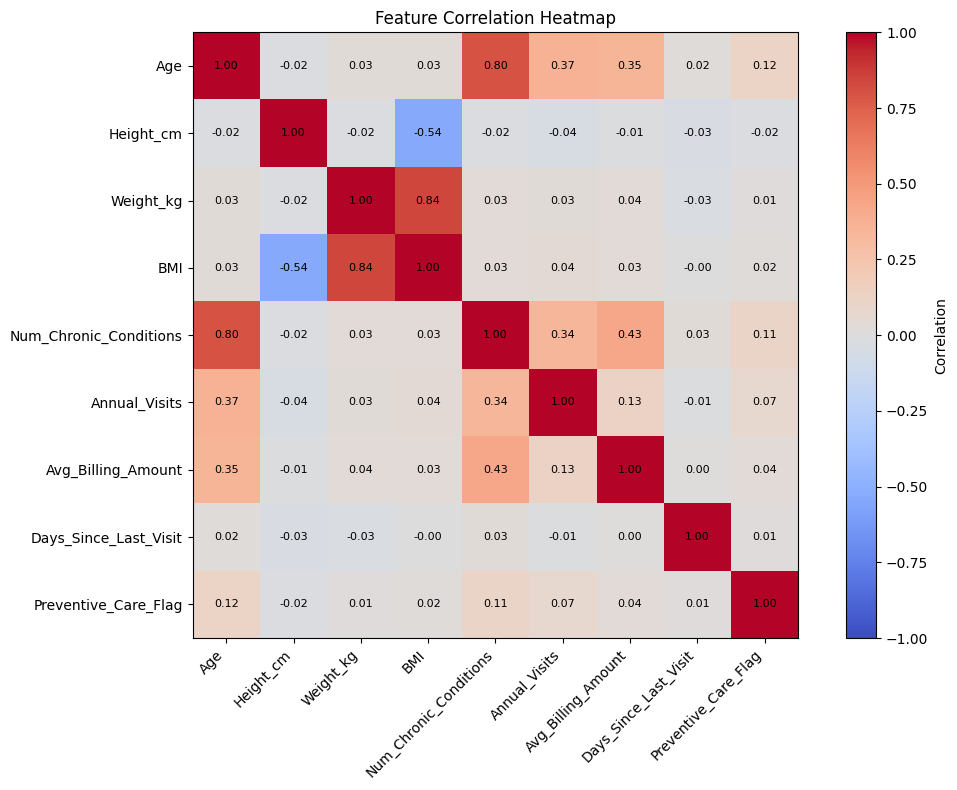

In [8]:
corr = ndf.corr()

plt.figure(figsize=(11, 8))

plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')

plt.xticks(range(len(corr.columns)), corr.columns,
           rotation=45, ha='right')
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}',
                 ha='center', va='center', fontsize=8)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


Observations :-
1. BMI and Weight have a high positive correlation of 0.80. 
2. BMI and Height have a high negative corrlation of 0.54
3. Age and Num_Chronic_Condition are also highly correlated. Age is also moderately correalted with Avg_Billing_Amount and Annual_Visits.
4. Similar moderate correlation is also between num_chronic and annual visits as well as avg billing amount.

Inference: 
1. BMI = Weight/height^2.  These three variables contain overlapping information. For now we can use only BMI.
2. Older patients in this dataset tend to have higher healthcare utilisation and biling.
3. We need to investigate the relation between num_chronic and annual visits.


In [9]:
#ndf = ndf.drop(columns = ['Height_cm','Weight_kg'])
ndf.columns = ndf.columns.str.lower()
X = ndf.copy()
X

,age,height_cm,weight_kg,bmi,num_chronic_conditions,annual_visits,avg_billing_amount,days_since_last_visit,preventive_care_flag
0,64,151,115,50.4,3,7,2995.0,186,0
1,59,189,68,19.0,1,8,1209.0,39,0
2,58,156,91,37.4,1,4,999.0,126,0
3,43,152,92,39.8,1,6,5638.5,286,1
4,53,167,51,18.3,1,4,5796.0,319,0
...,...,...,...,...,...,...,...,...,...
1995,37,195,109,28.7,0,4,4581.0,122,1
1996,32,151,94,41.2,0,1,329.0,150,1
1997,50,149,115,51.8,1,8,4942.5,242,1
1998,74,165,97,35.6,3,7,4700.0,195,1


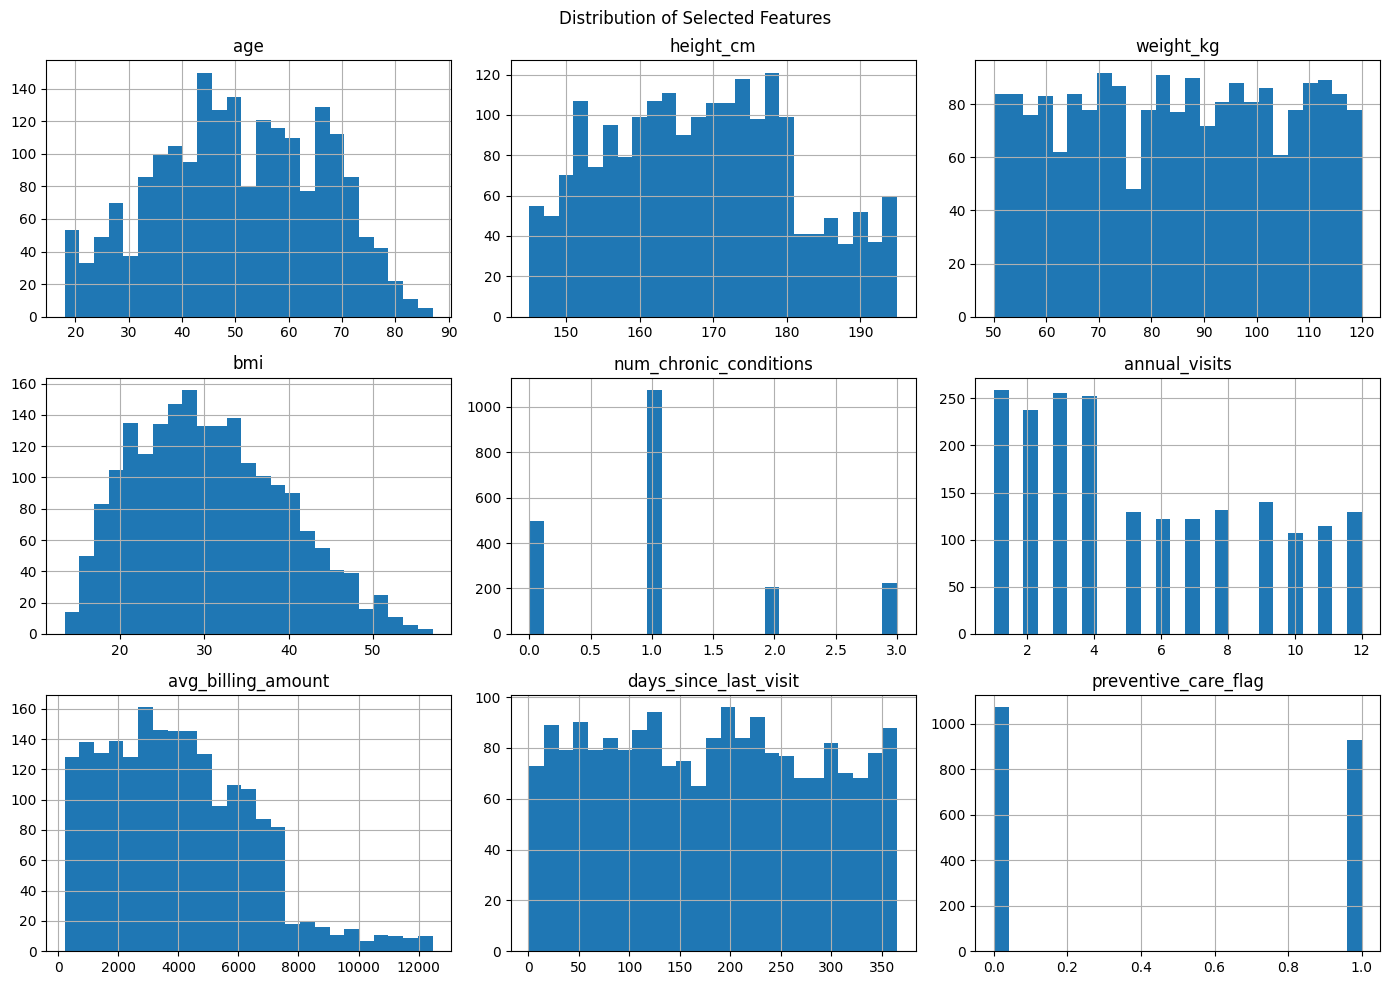

In [10]:
# checking the distribution before scaling :-> 
X.hist(figsize = (14,10), bins = 25)
plt.suptitle("Distribution of Selected Features")
plt.tight_layout() 
plt.show()

Observations :-
1. Age is normally distributed
2. BMI is right skewed
3. Num chronic , annual visits, preventive care flag are discrete distributions.
4. days_since_last visit is a uniform distribution.
5. avg_billing_amount -> right skewed distribution.

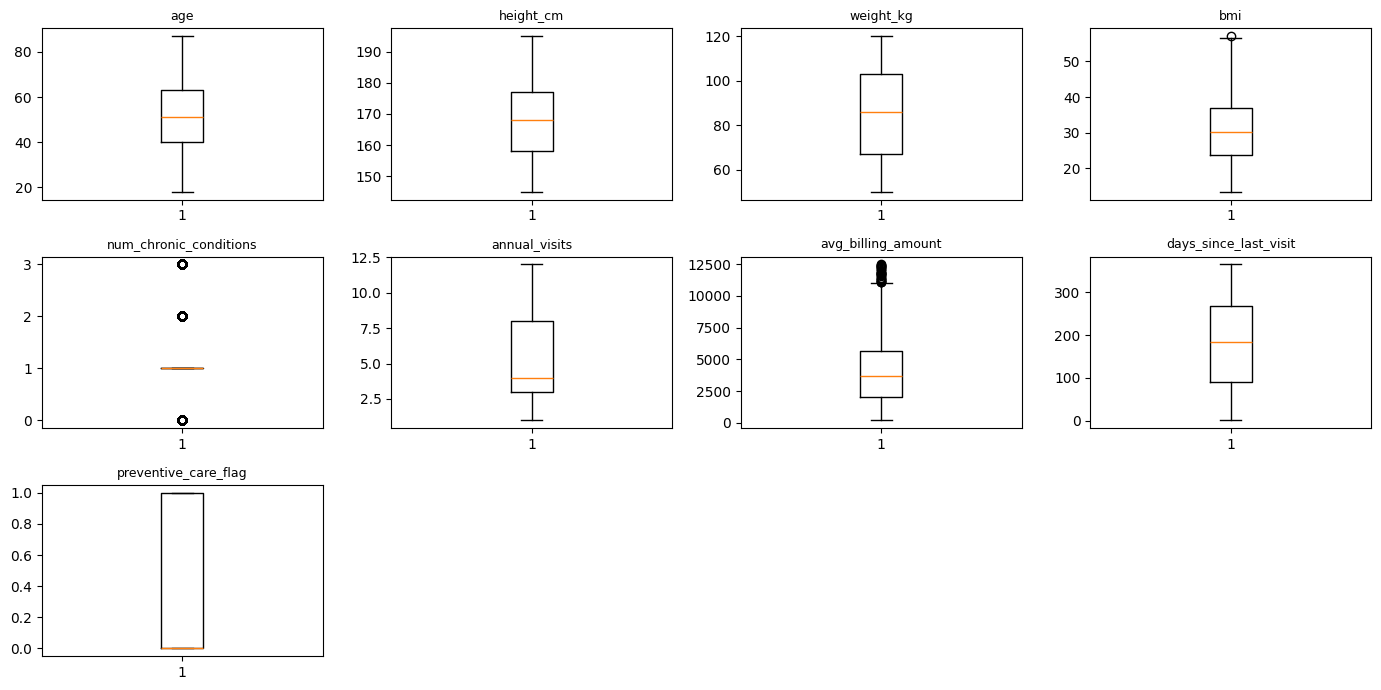

In [11]:
plt.figure(figsize = (14,7))
for i, col in enumerate(ndf.columns, 1):
    plt.subplot(3,4,i)
    plt.boxplot(X[col].dropna())
    plt.title(col, fontsize = 9)
plt.tight_layout() 
plt.show()

In [12]:
outlier_summary = []
features = ndf.columns

for col in features:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((X[col] < lower) | (X[col] > upper)).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Outlier Count": count,
        "Outlier %": round(count / len(X) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,age,5.12,98.12,0,0.00
1,height_cm,129.50,205.50,0,0.00
2,weight_kg,13.00,157.00,0,0.00
3,bmi,3.96,56.86,1,0.05
4,num_chronic_conditions,1.00,1.00,926,46.30
5,annual_visits,-4.50,15.50,0,0.00
6,avg_billing_amount,-3323.81,11035.69,28,1.40
7,days_since_last_visit,-177.00,535.00,0,0.00
8,preventive_care_flag,-1.50,2.50,0,0.00


In [13]:
ndf.skew()

age                      -0.105301
height_cm                 0.167846
weight_kg                -0.018466
bmi                       0.371679
num_chronic_conditions    0.795998
annual_visits             0.432123
avg_billing_amount        0.704701
days_since_last_visit     0.054967
preventive_care_flag      0.144483
dtype: float64

In [14]:
ndf.isnull().sum()

age                       0
height_cm                 0
weight_kg                 0
bmi                       0
num_chronic_conditions    0
annual_visits             0
avg_billing_amount        0
days_since_last_visit     0
preventive_care_flag      0
dtype: int64